# Employee Attrition Prediction & HR Analytics
**Python Programming for AI & Data Science project**

This project uses the HR Excel dataset to:
1. Explore employee information.
2. Understand patterns related to employee attrition.
3. Train simple machine-learning models to predict `Attrition` (Yes/No).
4. Compare model results.


In [ ]:
# Import Pandas to read and work with the dataset
import pandas as pd

from google.colab import files

print("Pandas is ready!")

Pandas is ready!


## 2. Upload and read the HR dataset


In [ ]:
uploaded = files.upload()
file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)


print("Dataset loaded successfully!")

Saving HR Data.xlsx to HR Data.xlsx
Dataset loaded successfully!


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (1470, 39)

Column names:
['Attrition', 'Business Travel', 'CF_age band', 'CF_attrition label', 'Department', 'Education Field', 'emp no', 'Employee Number', 'Gender', 'Job Role', 'Marital Status', 'Over Time', 'Over18', 'Training Times Last Year', 'Age', 'CF_current Employee', 'Daily Rate', 'Distance From Home', 'Education', 'Employee Count', 'Environment Satisfaction', 'Hourly Rate', 'Job Involvement', 'Job Level', 'Job Satisfaction', 'Monthly Income', 'Monthly Rate', 'Num Companies Worked', 'Percent Salary Hike', 'Performance Rating', 'Relationship Satisfaction', 'Standard Hours', 'Stock Option Level', 'Total Working Years', 'Work Life Balance', 'Years At Company', 'Years In Current Role', 'Years Since Last Promotion', 'Years With Curr Manager']

First 5 rows:


,Attrition,Business Travel,CF_age band,CF_attrition label,Department,Education Field,emp no,Employee Number,Gender,Job Role,...,Performance Rating,Relationship Satisfaction,Standard Hours,Stock Option Level,Total Working Years,Work Life Balance,Years At Company,Years In Current Role,Years Since Last Promotion,Years With Curr Manager
0,Yes,Travel_Rarely,35 - 44,Ex-Employees,Sales,Life Sciences,STAFF-1,1,Female,Sales Executive,...,3,1,80,0,8,1,6,4,0,5
1,No,Travel_Frequently,45 - 54,Current Employees,R&D,Life Sciences,STAFF-2,2,Male,Research Scientist,...,4,4,80,1,10,3,10,7,1,7
2,Yes,Travel_Rarely,35 - 44,Ex-Employees,R&D,Other,STAFF-4,4,Male,Laboratory Technician,...,3,2,80,0,7,3,0,0,0,0
3,No,Travel_Frequently,25 - 34,Current Employees,R&D,Life Sciences,STAFF-5,5,Female,Research Scientist,...,3,3,80,0,8,3,8,7,3,0
4,No,Travel_Rarely,25 - 34,Current Employees,R&D,Medical,STAFF-7,7,Male,Laboratory Technician,...,3,4,80,1,6,3,2,2,2,2


## 3. Check data quality


In [ ]:
print("Missing values in the dataset:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values in the dataset: 0
Duplicate rows: 0

Data types:
Attrition                     object
Business Travel               object
CF_age band                   object
CF_attrition label            object
Department                    object
Education Field               object
emp no                        object
Employee Number                int64
Gender                        object
Job Role                      object
Marital Status                object
Over Time                     object
Over18                        object
Training Times Last Year       int64
Age                            int64
CF_current Employee            int64
Daily Rate                     int64
Distance From Home             int64
Education                     object
Employee Count                 int64
Environment Satisfaction       int64
Hourly Rate                    int64
Job Involvement                int64
Job Level                      int64
Job Satisfaction               int64
Monthly Inc

## 5. Basic HR analysis
Count employees who stayed and employees who left.

In [ ]:
print("Attrition counts:")
print(df["Attrition"].value_counts())

print("\nAttrition percentage:")
print((df["Attrition"].value_counts(normalize=True) * 100).round(2))

Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition percentage:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


In [ ]:
# Import these libraries now because we are starting data visualization
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries are ready!")

Visualization libraries are ready!


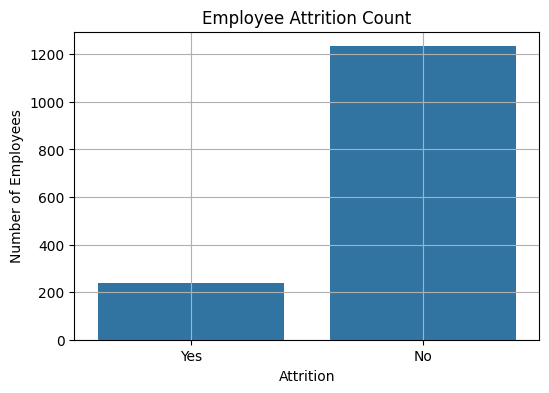

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Employee Attrition Count")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.grid()
plt.show()

## 6. Explore attrition by department and overtime
These charts help us see how attrition is distributed. They do not prove that a factor causes employees to leave.

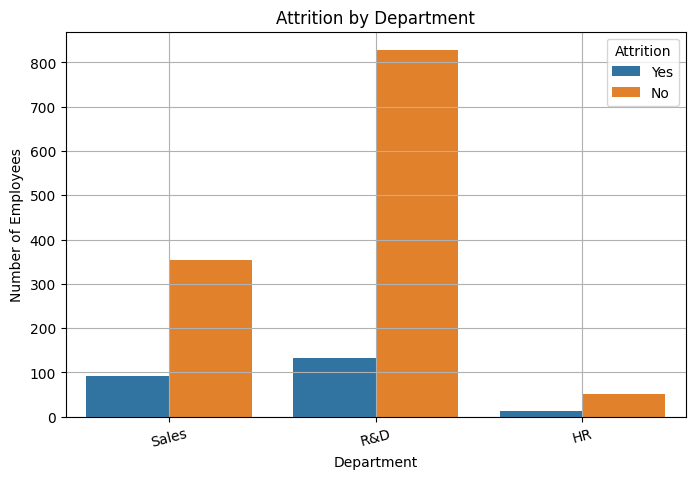

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Department", hue="Attrition")
plt.title("Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)
plt.grid()
plt.show()

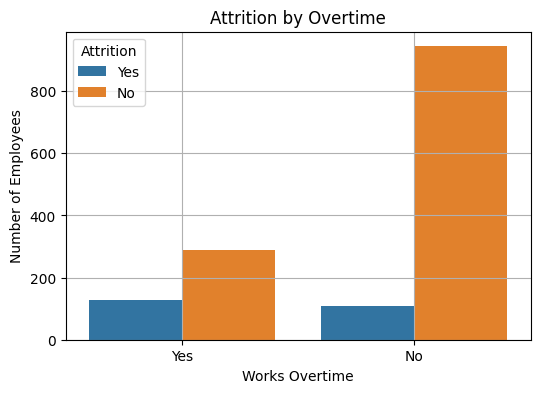

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Over Time", hue="Attrition")
plt.title("Attrition by Overtime")
plt.xlabel("Works Overtime")
plt.ylabel("Number of Employees")
plt.grid()
plt.show()

## 7. Compare monthly income


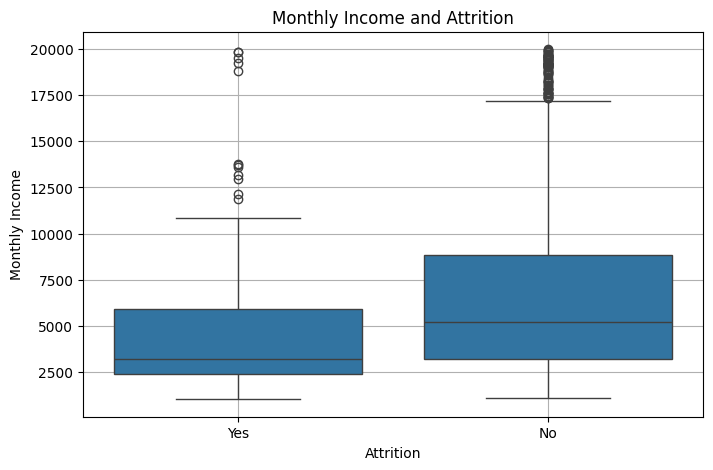

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Attrition", y="Monthly Income")
plt.title("Monthly Income and Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")
plt.grid()
plt.show()

## 8. Compare job satisfaction


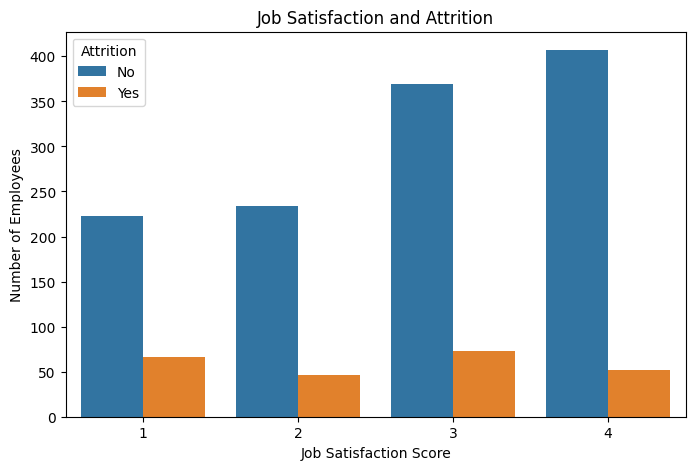

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Job Satisfaction", hue="Attrition")
plt.title("Job Satisfaction and Attrition")
plt.xlabel("Job Satisfaction Score")
plt.ylabel("Number of Employees")
plt.show()

## 9. Prepare the data for machine learning

- `Attrition` is the answer (target) that the model will learn to predict.
- We remove employee ID columns because they do not describe employee behaviour.
- We also remove `CF_attrition label` and `CF_current Employee`: these columns directly reveal the attrition outcome and would cause **data leakage**.
- Constant columns such as `Employee Count`, `Standard Hours` and `Over18` do not help the model.
- Text categories are converted into numbers using one-hot encoding.

In [ ]:
# Separate the answer (target) from the input information
y = df["Attrition"].map({"Yes": 1, "No": 0})

# Remove columns that should not be used as model inputs
columns_to_drop = [
    "Attrition",
    "CF_attrition label",
    "CF_current Employee",
    "Employee Number",
    "emp no",
    "Employee Count",
    "Standard Hours",
    "Over18",
    "CF_age band"
]

X = df.drop(columns=columns_to_drop, errors="ignore")

# Convert text columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)
display(X.head())

Input data shape: (1470, 47)
Target data shape: (1470,)


,Training Times Last Year,Age,Daily Rate,Distance From Home,Environment Satisfaction,Hourly Rate,Job Involvement,Job Level,Job Satisfaction,Monthly Income,...,Job Role_Research Scientist,Job Role_Sales Executive,Job Role_Sales Representative,Marital Status_Married,Marital Status_Single,Over Time_Yes,Education_Bachelor's Degree,Education_Doctoral Degree,Education_High School,Education_Master's Degree
0,0,41,1102,1,2,94,3,2,4,5993,...,False,True,False,False,True,True,False,False,False,False
1,3,49,279,8,3,61,2,2,2,5130,...,True,False,False,True,False,False,False,False,True,False
2,3,37,1373,2,4,92,2,1,3,2090,...,False,False,False,False,True,True,False,False,False,False
3,3,33,1392,3,4,56,3,1,3,2909,...,True,False,False,True,False,True,False,False,False,True
4,3,27,591,2,1,40,3,1,2,3468,...,False,False,False,True,False,False,False,False,True,False


## 10. Split the data into training and testing sets
I used 80% of the records to train the model and 20% to test it. Stratification keeps the Yes/No ratio similar in both sets.

In [ ]:
# Import the tools needed for machine learning
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Machine-learning libraries are ready!")

Machine-learning libraries are ready!


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1176
Testing records: 294


## 11. Train three machine-learning models
I used will compare Logistic Regression, Decision Tree and Random Forest. These are standard classification algorithms.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

results = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    results[model_name] = accuracy

    print("\n", model_name)
    print("Accuracy:", round(accuracy * 100, 2), "%")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



 Logistic Regression
Accuracy: 76.53 %

 Decision Tree
Accuracy: 78.91 %

 Random Forest
Accuracy: 84.69 %


## 12. Compare model accuracy


,Model,Accuracy
2,Random Forest,0.846939
1,Decision Tree,0.789116
0,Logistic Regression,0.765306


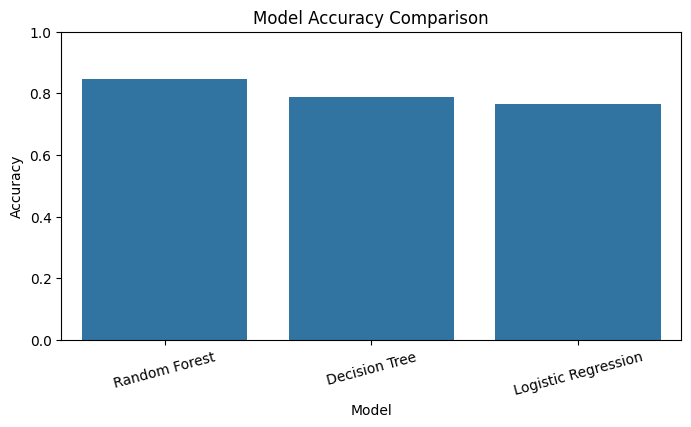

In [ ]:
results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": list(results.values())
}).sort_values("Accuracy", ascending=False)

display(results_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

## 13. Evaluate the best model more carefully

The dataset has fewer employees who left than employees who stayed. Therefore, also check **precision, recall and F1-score** for the `Yes` class. Recall tells us what fraction of employees who actually left were identified by the model.

The code selects the model with the highest test accuracy for this simple comparison. For a more advanced study, model selection should prioritize the metric that best matches the project goal.

In [ ]:
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

best_predictions = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

Selected model: Random Forest

Classification Report:
              precision    recall  f1-score   support

 Stayed (No)       0.85      0.99      0.92       247
  Left (Yes)       0.62      0.11      0.18        47

    accuracy                           0.85       294
   macro avg       0.74      0.55      0.55       294
weighted avg       0.82      0.85      0.80       294



## 14. Confusion matrix
The confusion matrix shows correct and incorrect predictions for employees who stayed and left.

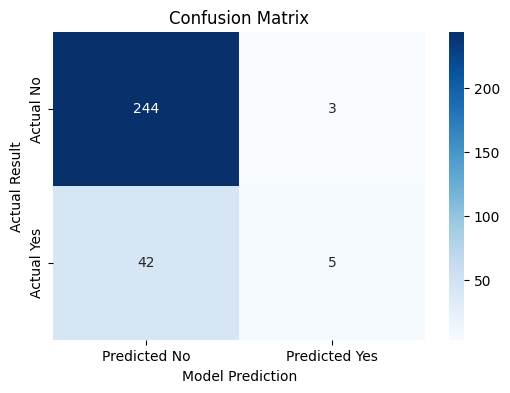

In [ ]:
cm = confusion_matrix(y_test, best_predictions, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.title("Confusion Matrix")
plt.xlabel("Model Prediction")
plt.ylabel("Actual Result")
plt.show()

## 15. See the most important features (Random Forest)
This section uses the Random Forest model to show which input features were most useful to that model. Feature importance does not prove cause and effect.

,Feature,Importance
9,Monthly Income,0.069205
1,Age,0.064244
18,Years At Company,0.051047
2,Daily Rate,0.049749
42,Over Time_Yes,0.048278
10,Monthly Rate,0.047743
16,Total Working Years,0.046226
3,Distance From Home,0.044409
5,Hourly Rate,0.042994
21,Years With Curr Manager,0.037863


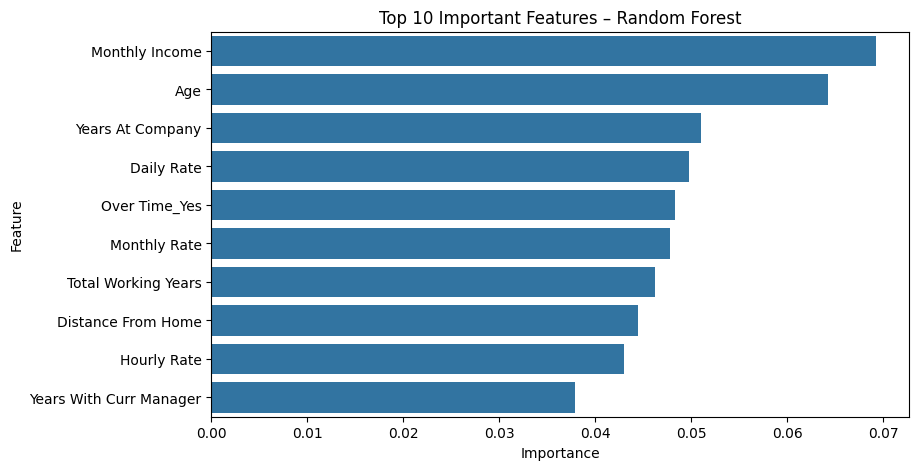

In [ ]:
rf_model = models["Random Forest"]

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False).head(10)

display(importance)

plt.figure(figsize=(9, 5))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Top 10 Important Features – Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## 16. Try a prediction on one test record
This uses one record from the test set as an example. It does not ask for new employee details.

In [ ]:
sample_employee = X_test.iloc[[0]]
actual_value = y_test.iloc[0]

predicted_value = best_model.predict(sample_employee)[0]
predicted_label = "Yes – likely to leave" if predicted_value == 1 else "No – likely to stay"
actual_label = "Yes – left" if actual_value == 1 else "No – stayed"

print("Model prediction:", predicted_label)
print("Actual dataset result:", actual_label)

Model prediction: No – likely to stay
Actual dataset result: No – stayed


## Project conclusion

This project analysed an HR dataset and trained machine-learning classification models to estimate employee attrition. It included data checking, visual analysis, data preparation, model training and model evaluation.

